In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import cv2 as cv

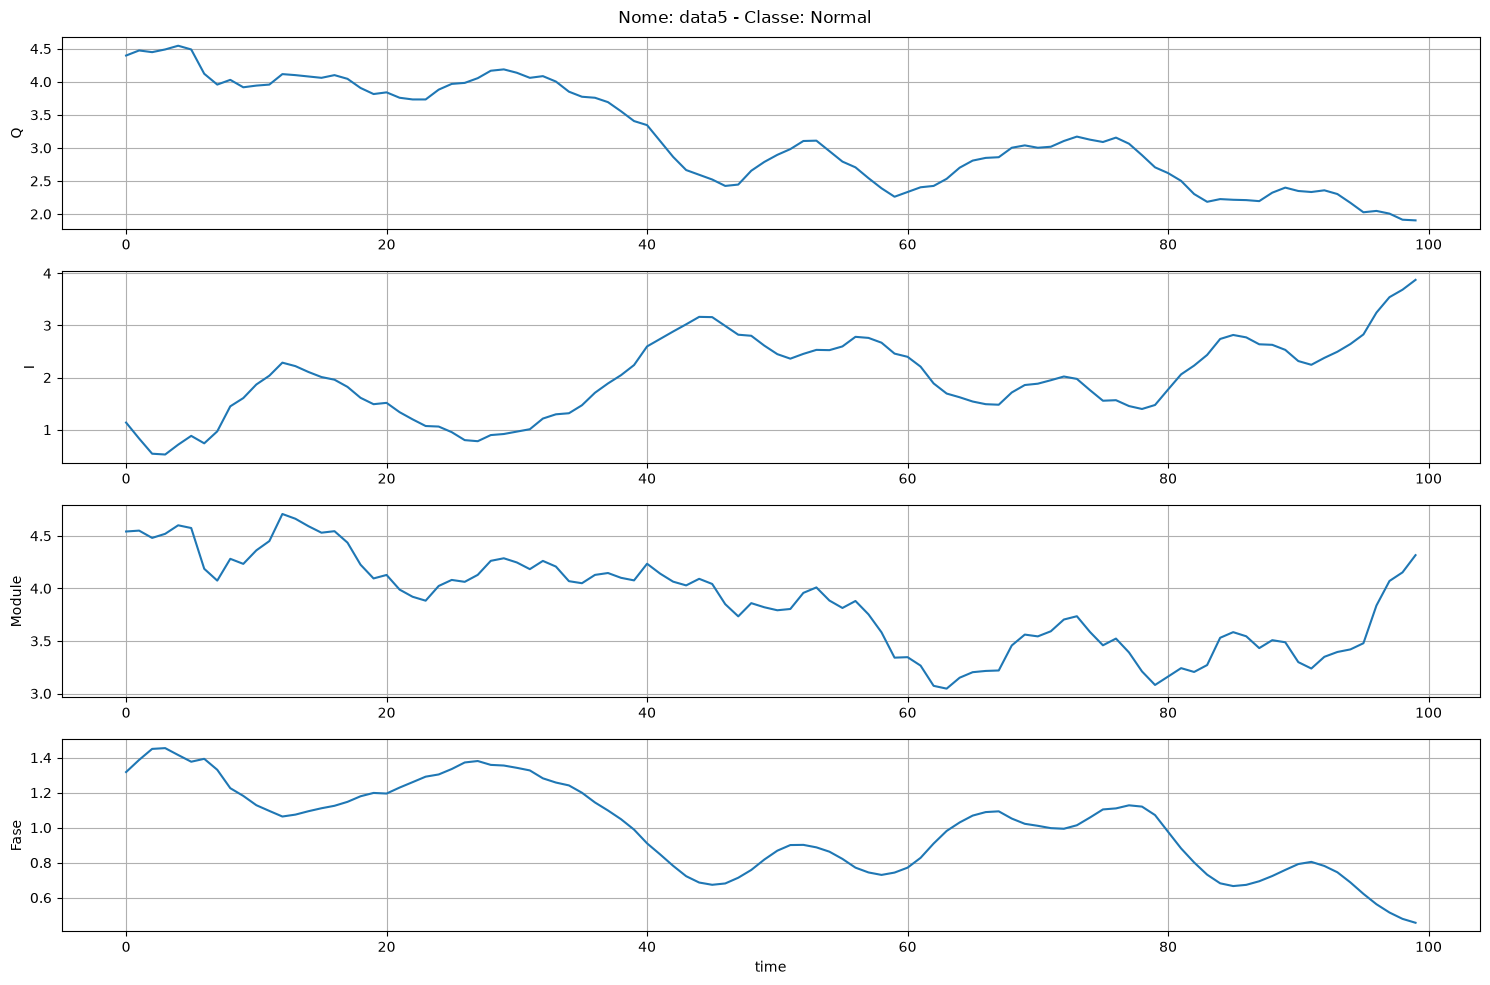

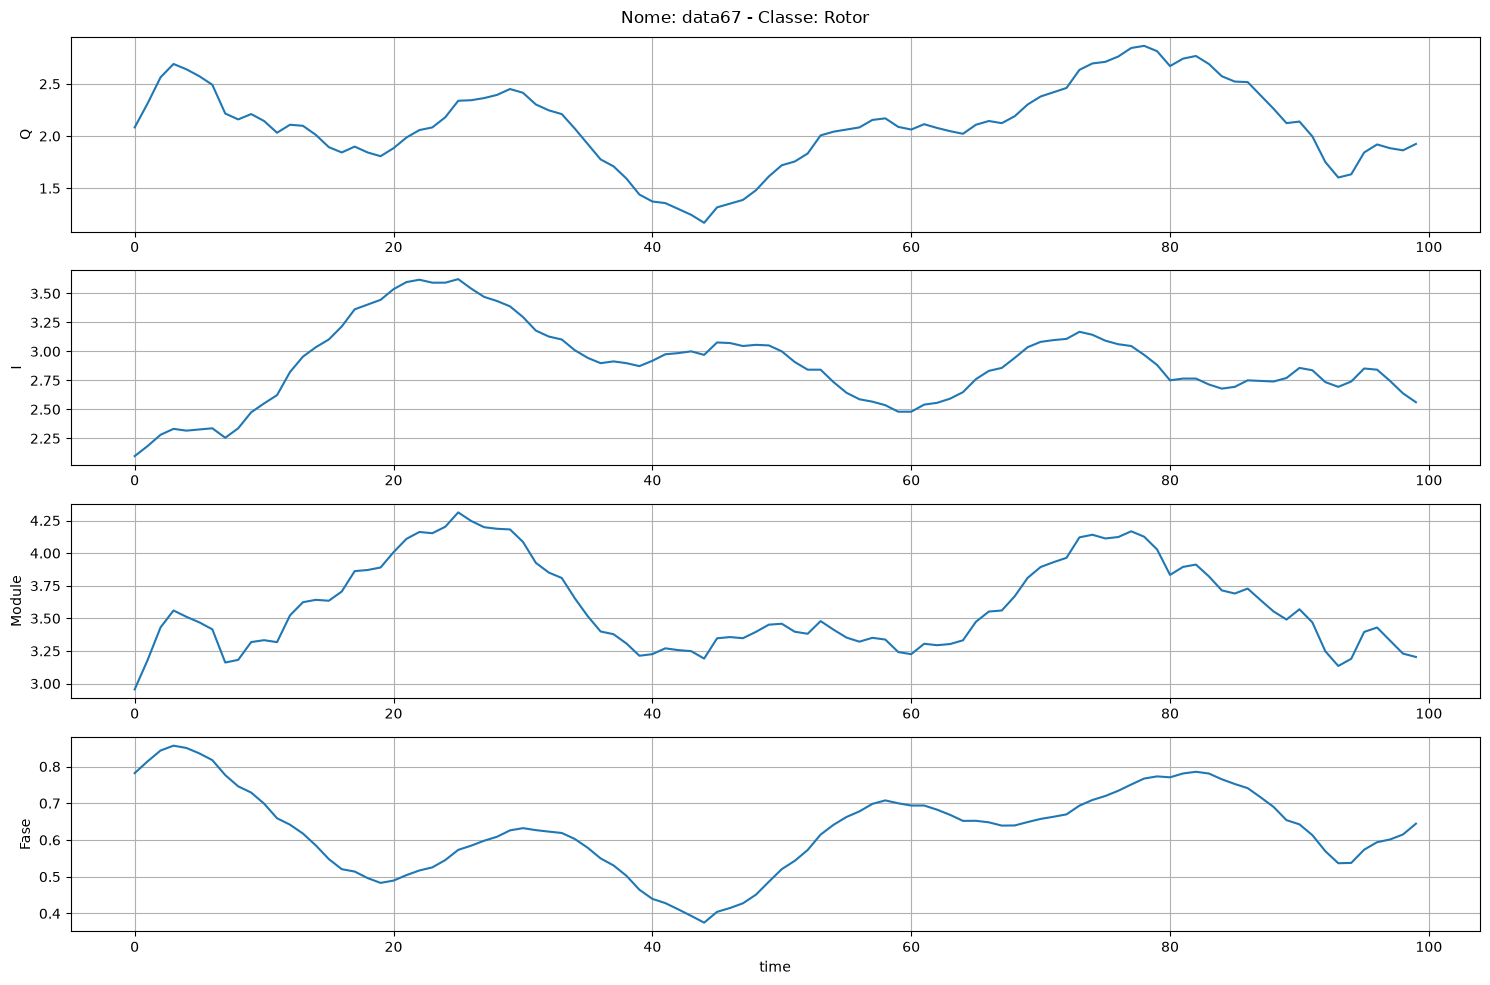

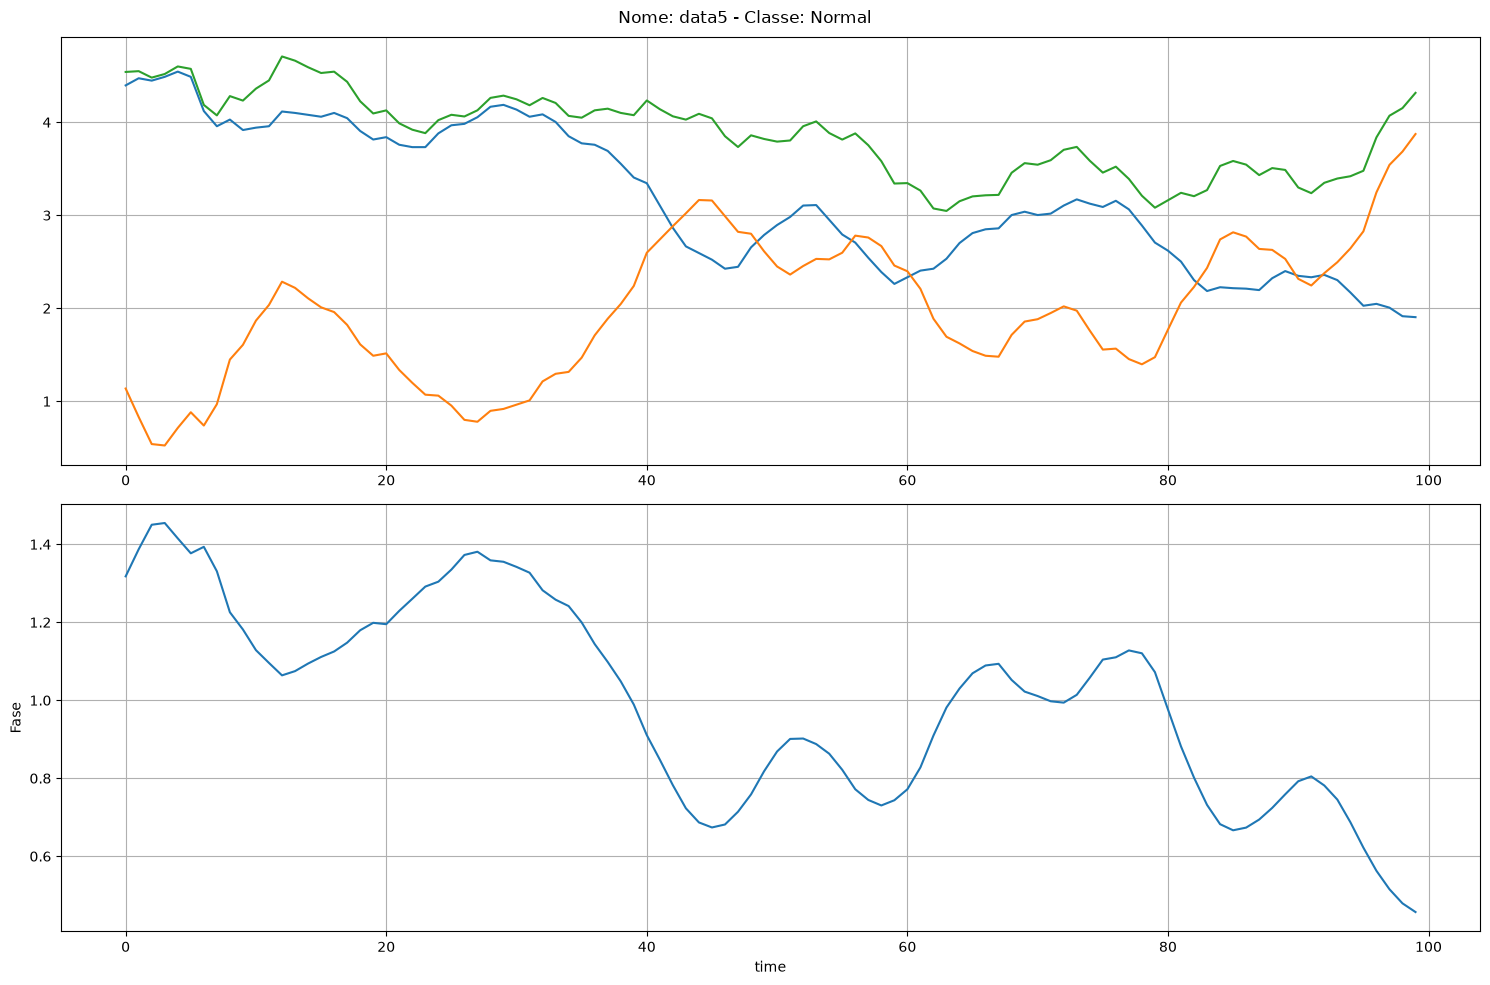

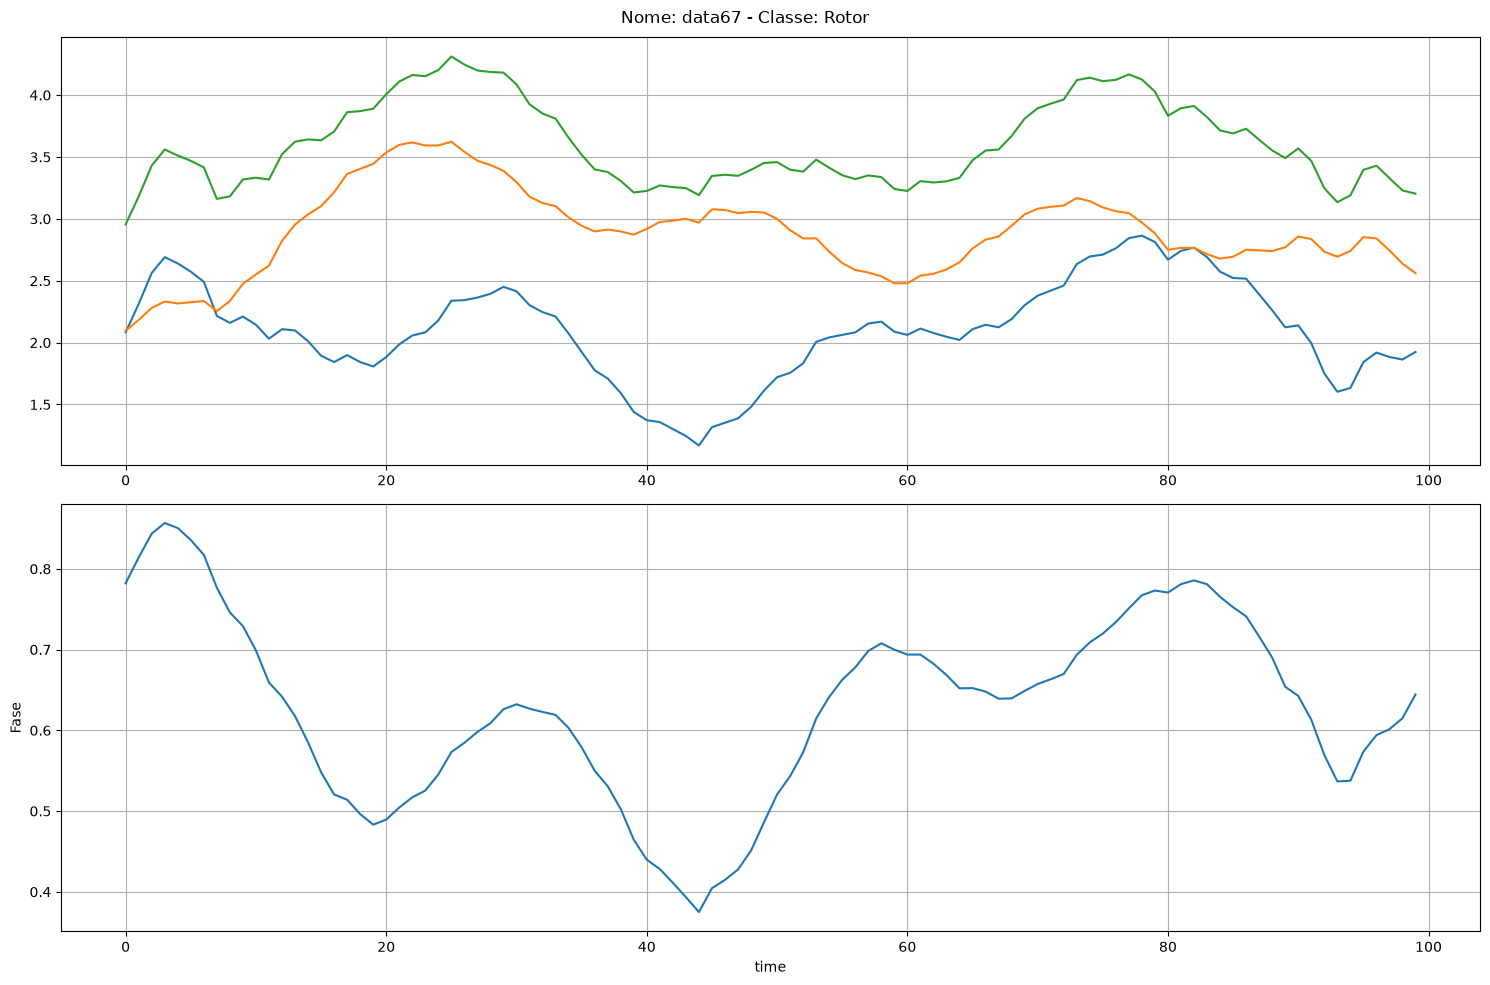

In [87]:
dataset_path = "./dataset/radar-data-for-machine-fault-detection/dataset"
dataset_data_details = dataset_path + "/Data_Details.csv"

def load_dataDetails():
    df_details = pd.read_csv(dataset_data_details, sep=";") # lendo arquivo
    df_details = df_details.iloc[:, :-1] # removendo último coluna

    # Renomeando colunas
    df_details = df_details.rename(columns={
        "Data_name":"dataName",
        "Motor speed (rpm)":"motorSpeed",
        "Load (Nm)":"load",
        "Class":"class"
        })

    # Adicionando caminho dos dados brutos
    df_details["rawData"] = dataset_path + "/raw_data/" + \
        df_details["class"].str.lower().str.split(' ', n=1).str[0] + "/" + \
        df_details["dataName"] + ".csv"

    return df_details

def load_rawData(dataFile):
    df_rawData = pd.read_csv(dataFile, sep=",",decimal=".") # lendo arquivo

    df_rawData["module"] = np.sqrt(np.pow(df_rawData["Q_data"],2) + np.pow(df_rawData["I_data"],2)) # Calculando modulo do sinal
    df_rawData["fase"] = np.atan(df_rawData["Q_data"]/df_rawData["I_data"]) # Calculando fase do sinal

    df_rawData = df_rawData[df_rawData["module"] > 0] # Filtrando valores não nulos

    return df_rawData


def plot_rawData_separeted(data_detail, intervalo=(0,0)):
    data_rawData = load_rawData(data_detail["rawData"])

    if intervalo != (0,0): data_rawData = data_rawData[intervalo[0]:intervalo[1]]

    fig, axs = plt.subplots(4,1,figsize=(15,10))

    axs[0].plot(np.arange(data_rawData.shape[0]), data_rawData["Q_data"])
    axs[0].set_ylabel("Q")
    axs[0].grid(True)

    axs[1].plot(np.arange(data_rawData.shape[0]), data_rawData["I_data"])
    axs[1].set_ylabel("I")
    axs[1].grid(True)

    axs[2].plot(np.arange(data_rawData.shape[0]), data_rawData["module"])
    axs[2].set_ylabel("Module")
    axs[2].grid(True)

    axs[3].plot(np.arange(data_rawData.shape[0]), data_rawData["fase"])
    axs[3].set_ylabel("Fase")
    axs[3].grid(True)

    title = f"Nome: {data_detail['dataName']} - Classe: {data_detail['class']}"
    plt.suptitle(title)

    plt.xlabel("time")
    plt.tight_layout()
    plt.show()

def plot_rawData_together(data_detail, intervalo=(0,0)):
    data_rawData = load_rawData(data_detail["rawData"])

    if intervalo != (0,0): data_rawData = data_rawData[intervalo[0]:intervalo[1]]

    fig, axs = plt.subplots(2,1,figsize=(15,10))

    axs[0].plot(np.arange(data_rawData.shape[0]), data_rawData["Q_data"])
    axs[0].grid(True)

    axs[0].plot(np.arange(data_rawData.shape[0]), data_rawData["I_data"])
    axs[0].grid(True)

    axs[0].plot(np.arange(data_rawData.shape[0]), data_rawData["module"])
    axs[0].grid(True)

    axs[1].plot(np.arange(data_rawData.shape[0]), data_rawData["fase"])
    axs[1].set_ylabel("Fase")
    axs[1].grid(True)

    title = f"Nome: {data_detail['dataName']} - Classe: {data_detail['class']}"
    plt.suptitle(title)

    plt.xlabel("time")
    plt.tight_layout()
    plt.show()


df_dataDetails = load_dataDetails()
print("")

plot_rawData_separeted(df_dataDetails[df_dataDetails["class"] == "Normal"].iloc[4], (0,100))
plot_rawData_separeted(df_dataDetails[df_dataDetails["class"] == "Rotor"].iloc[0], (0,100))

plot_rawData_together(df_dataDetails[df_dataDetails["class"] == "Normal"].iloc[4], (0,100))
plot_rawData_together(df_dataDetails[df_dataDetails["class"] == "Rotor"].iloc[0], (0,100))

